# Gezichtsherkenning: transfer learning en contrastive learning

**Topic 3 — PXL · van foto naar "wie is dit?"**

---

## Wat we gaan bouwen

Aan het eind van deze notebook heb je een werkend gezichtsherkenningssysteem dat een foto
krijgt en er een naam bij zegt. **En je kunt er je eigen foto in stoppen.**

Het interessante is *hoe* we dat doen. We trainen namelijk geen gezichtsmodel — dat zou
miljoenen foto's en dagen rekentijd kosten. In plaats daarvan gebruiken we twee ideeën die je
overal in de moderne AI tegenkomt:

| Idee | Wat het betekent | Waar je het hier ziet |
|---|---|---|
| **Transfer learning** | Neem een netwerk dat al iets geleerd heeft, en gebruik die kennis voor jouw probleem | §3: FaceNet zet elk gezicht om in 512 getallen |
| **Contrastive learning** | Leer niet "wat is dit?" maar "welke twee horen bij elkaar?" | §6 en §7: twee eigen modellen die met paren werken |

## De opzet

```
   foto  ──►  [1] gezicht vinden  ──►  [2] embedding maken  ──►  [3] ons eigen model  ──►  naam
              MTCNN                    FaceNet                    Keras
              (bounding box)           (512 getallen)             (dat trainen we zelf)
```

Stap 1 en 2 zijn kant-en-klare modellen — dat is de transfer learning. **Stap 3 schrijven we
helemaal zelf in Keras**, en dat is precies het stuk dat het voor jouw gezichten laat werken.

## Inhoud

1. De foto's
2. Gezichten vinden met MTCNN
3. Van gezicht naar embedding
4. De embeddingruimte verkennen
5. Ons eigen model: wie is dit?
6. Contrastive learning: de ruimte verbouwen (triplet loss)
7. Of: de vergelijking zelf leren (pairwise model)
8. Je eigen foto

## 0. Setup

In [1]:
import warnings, os
warnings.filterwarnings("ignore")
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"      # TensorFlow wat stiller maken

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from PIL import Image

import keras
from keras import layers, ops

from sklearn.decomposition import PCA
from sklearn.metrics import roc_auc_score, roc_curve

# De twee voorgetrainde modellen die we lenen.
from mtcnn import MTCNN                    # gezichten vinden
from keras_facenet import FaceNet          # gezichten omzetten in getallen

%matplotlib inline
plt.rcParams["figure.dpi"] = 110

RANDOM_STATE = 42
keras.utils.set_random_seed(RANDOM_STATE)
rng = np.random.default_rng(RANDOM_STATE)

print("keras     ", keras.__version__, "| backend:", keras.backend.backend())
import tensorflow as tf; print("tensorflow", tf.__version__)

keras      3.15.1 | backend: tensorflow
tensorflow 2.21.0


## 1. De foto's

We gebruiken **LFW** (Labeled Faces in the Wild): foto's van bekende personen, zoals ze op het
internet gevonden zijn. Geen studiofoto's dus — wisselend licht, verschillende hoeken,
brillen, microfoons voor het gezicht. Precies wat je wil om te testen of iets robuust is.

`haal_data.py` heeft er 16 personen uit gehaald met elk 40 foto's, en die als losse JPEG's
neergezet. De mappenstructuur *is* de dataset:

```
data/gezichten/
├── George_W_Bush/0001.jpg ...
├── Colin_Powell/0001.jpg ...
└── ...
```

Wil je later je eigen gezicht toevoegen, dan maak je gewoon zo'n map bij. Meer is het niet.

In [2]:
MAP = Path("data/gezichten")
if not MAP.exists():
    raise FileNotFoundError(
        "Foto's niet gevonden. Draai eerst eenmalig:  .venv/bin/python haal_data.py")

paden  = sorted(MAP.rglob("*.jpg"))
namen  = np.array([p.parent.name.replace("_", " ") for p in paden])
personen = sorted(set(namen))

print(f"{len(paden)} foto's van {len(personen)} personen")
for p in personen:
    print(f"   {p:28s} {(namen == p).sum():3d} foto's")

640 foto's van 16 personen
   Ariel Sharon                  40 foto's
   Colin Powell                  40 foto's
   Donald Rumsfeld               40 foto's
   George W Bush                 40 foto's
   Gerhard Schroeder             40 foto's
   Gloria Macapagal Arroyo       40 foto's
   Hugo Chavez                   40 foto's
   Jacques Chirac                40 foto's
   Jean Chretien                 40 foto's
   Jennifer Capriati             40 foto's
   John Ashcroft                 40 foto's
   Junichiro Koizumi             40 foto's
   Luiz Inacio Lula da Silva     40 foto's
   Serena Williams               40 foto's
   Tony Blair                    40 foto's
   Vladimir Putin                40 foto's


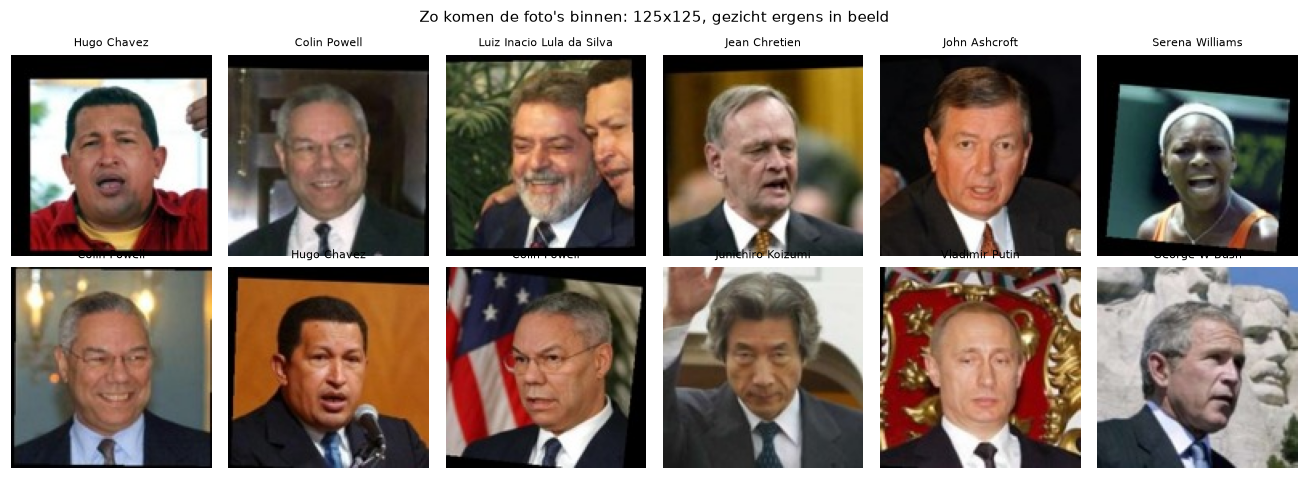

In [3]:
# Een willekeurige greep, zodat je ziet waar we mee werken.
fig, assen = plt.subplots(2, 6, figsize=(12, 4.4))
for ax, k in zip(assen.ravel(), rng.choice(len(paden), 12, replace=False)):
    ax.imshow(Image.open(paden[k]))
    ax.set_title(namen[k], fontsize=7)
    ax.axis("off")
fig.suptitle("Zo komen de foto's binnen: 125x125, gezicht ergens in beeld", fontsize=10)
plt.tight_layout()
plt.show()

---

## 2. Gezichten vinden met MTCNN

Voor je iets over een gezicht kunt zeggen, moet je het eerst **vinden**. Dat is een apart
probleem, en we lossen het op met **MTCNN** (Multi-task Cascaded Convolutional Networks).

MTCNN kijkt in drie rondes naar de foto. Ronde één zet grof duizenden kandidaat-kadertjes uit,
ronde twee gooit de onzin weg, ronde drie verfijnt wat overblijft en zoekt meteen vijf
**landmarks**: twee ogen, de neus en twee mondhoeken.

Dat we die landmarks krijgen is geen extraatje — daarmee kun je het gezicht rechtzetten
voordat je het doorstuurt, en dat maakt de rest een stuk betrouwbaarder.

In [4]:
detector = MTCNN()

# Eén foto, om te zien wat eruit komt.
voorbeeld = np.array(Image.open(paden[0]).convert("RGB"))
gevonden  = detector.detect_faces(voorbeeld)

print(f"gevonden gezichten: {len(gevonden)}")
for g in gevonden:
    print(f"  box (x, y, breedte, hoogte): {g['box']}")
    print(f"  zekerheid                  : {g['confidence']:.4f}")
    print(f"  landmarks                  : {list(g['keypoints'])}")

Exception ignored in: <_io.BufferedReader>
Traceback (most recent call last):
  File "/Users/kristofslechten/Documents/Development/pxl/03-gezichtsherkenning/.venv/lib/python3.13/site-packages/lz4/frame/__init__.py", line 753, in flush
    self._fp.flush()
ValueError: I/O operation on closed file.
Exception ignored in: <_io.BufferedReader>
Traceback (most recent call last):
  File "/Users/kristofslechten/Documents/Development/pxl/03-gezichtsherkenning/.venv/lib/python3.13/site-packages/lz4/frame/__init__.py", line 753, in flush
    self._fp.flush()
ValueError: I/O operation on closed file.
Exception ignored in: <_io.BufferedReader>
Traceback (most recent call last):
  File "/Users/kristofslechten/Documents/Development/pxl/03-gezichtsherkenning/.venv/lib/python3.13/site-packages/lz4/frame/__init__.py", line 753, in flush
    self._fp.flush()
ValueError: I/O operation on closed file.


gevonden gezichten: 2
  box (x, y, breedte, hoogte): [36, 29, 47, 68]
  zekerheid                  : 0.9995
  landmarks                  : ['nose', 'mouth_right', 'right_eye', 'left_eye', 'mouth_left']
  box (x, y, breedte, hoogte): [83, 0, 31, 25]
  zekerheid                  : 0.9525
  landmarks                  : ['nose', 'mouth_right', 'right_eye', 'left_eye', 'mouth_left']


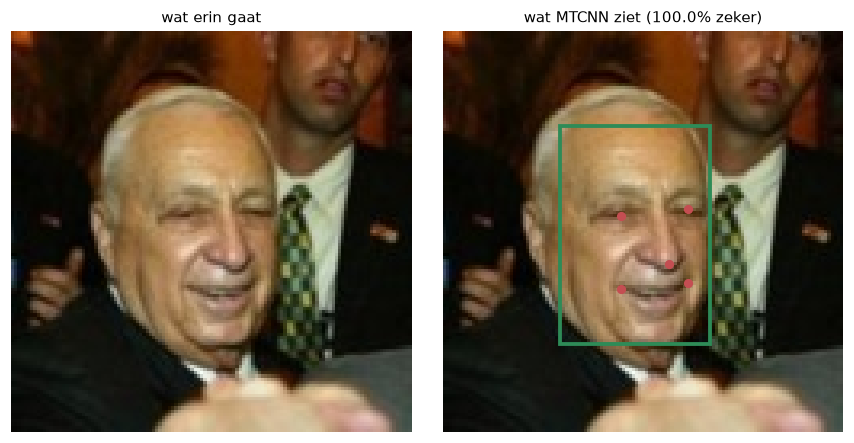

In [5]:
# Hetzelfde, maar dan zichtbaar.
fig, (a, b) = plt.subplots(1, 2, figsize=(8, 4))

a.imshow(voorbeeld); a.set_title("wat erin gaat", fontsize=10); a.axis("off")

b.imshow(voorbeeld)
x, y, w, h = gevonden[0]["box"]
b.add_patch(plt.Rectangle((x, y), w, h, fill=False, ec="#2E8B57", lw=2.5))
for naam_punt, (px, py) in gevonden[0]["keypoints"].items():
    b.plot(px, py, "o", ms=5, color="#C44E52")
b.set_title(f"wat MTCNN ziet ({gevonden[0]['confidence']:.1%} zeker)", fontsize=10)
b.axis("off")

plt.tight_layout()
plt.show()

### Alle foto's door de detector

Nu draaien we dit over de hele verzameling. Voor elk gezicht knippen we de bounding box uit en
schalen we naar 160×160 — dat is de maat die FaceNet verwacht.

> **Let op de teller onderaan.** Een detector die gezichten mist, is een detector die
> stilletjes rijen uit je dataset laat vallen. Dat wil je weten, niet vermoeden.

In [6]:
def knip_gezicht(pad, marge=0.15):
    # Geeft een 160x160 uitsnede terug, of None als er geen gezicht gevonden wordt.
    foto = np.array(Image.open(pad).convert("RGB"))
    kandidaten = detector.detect_faces(foto)
    if not kandidaten:
        return None

    # Meerdere gezichten? Neem het meest zekere.
    beste = max(kandidaten, key=lambda d: d["confidence"])
    x, y, w, h = beste["box"]

    # Een beetje marge eromheen: het kaartje zit vaak strak om de neus en kin.
    dx, dy = int(w * marge), int(h * marge)
    x, y = max(0, x - dx), max(0, y - dy)
    uitsnede = foto[y:y + h + 2 * dy, x:x + w + 2 * dx]
    if uitsnede.size == 0:
        return None

    return np.array(Image.fromarray(uitsnede).resize((160, 160)))


# We houden ook bij WELKE paden gelukt zijn, zodat foto's, uitsnedes en labels
# gegarandeerd op dezelfde index blijven staan. Mislukt er later toch een detectie,
# dan schuift er niets stiekem door elkaar.
gezichten, labels, paden_ok, mislukt = [], [], [], []
for pad, naam in zip(paden, namen):
    uitsnede = knip_gezicht(pad)
    if uitsnede is None:
        mislukt.append(pad)
        continue
    gezichten.append(uitsnede)
    labels.append(naam)
    paden_ok.append(pad)

gezichten = np.array(gezichten)
labels    = np.array(labels)
paden_ok  = np.array(paden_ok)

print(f"gezichten uitgeknipt : {len(gezichten)}")
print(f"geen gezicht gevonden: {len(mislukt)}")
print(f"vorm                 : {gezichten.shape}")

gezichten uitgeknipt : 640
geen gezicht gevonden: 0
vorm                 : (640, 160, 160, 3)


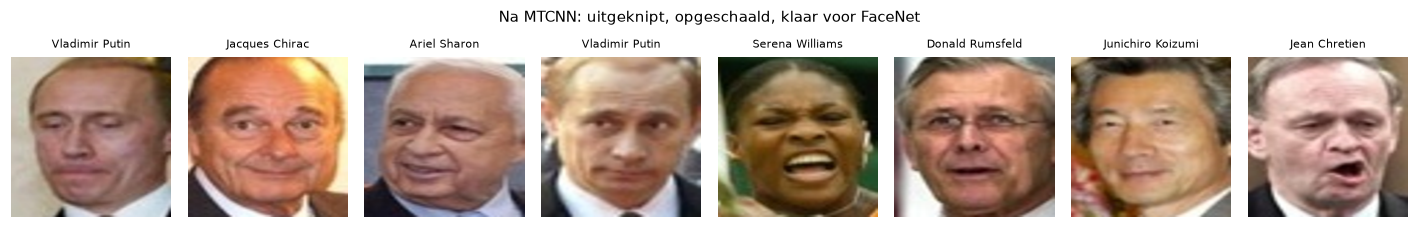

In [7]:
fig, assen = plt.subplots(1, 8, figsize=(13, 2.1))
for ax, k in zip(assen, np.random.default_rng(1).choice(len(gezichten), 8, replace=False)):
    ax.imshow(gezichten[k]); ax.set_title(labels[k], fontsize=7); ax.axis("off")
fig.suptitle("Na MTCNN: uitgeknipt, opgeschaald, klaar voor FaceNet", fontsize=10)
plt.tight_layout()
plt.show()

---

## 3. Van gezicht naar embedding

Nu het stuk waar transfer learning gebeurt.

**FaceNet** is een netwerk dat getraind is op miljoenen gezichten van duizenden mensen. Het is
niet getraind om namen te voorspellen — het is getraind om van elk gezicht een **lijstje van 512
getallen** te maken met één eigenschap:

> Twee foto's van **dezelfde** persoon krijgen lijstjes die dicht bij elkaar liggen.
> Twee foto's van **verschillende** personen krijgen lijstjes die ver uit elkaar liggen.

Zo'n lijstje heet een **embedding**. Je kunt het zien als een vingerafdruk: geen plaatje meer,
maar een positie in een ruimte van 512 dimensies, waar "dichtbij" letterlijk "lijkt op" betekent.

En dat is precies wat wij kunnen lenen. Wij hoeven FaceNet niets te leren — we gebruiken alleen
zijn uitvoer.

In [8]:
embedder = FaceNet()

# Alle uitsnedes in één keer door het netwerk.
embeddings = embedder.embeddings(gezichten)

print(f"vorm: {embeddings.shape}   ({embeddings.shape[0]} gezichten x {embeddings.shape[1]} getallen)")
print(f"lengte van elke vector: {np.linalg.norm(embeddings, axis=1)[:5].round(3)}")
print()
print("Alle vectoren hebben lengte 1: ze liggen op een bol. Dat is handig,")
print("want dan is 'afstand' hetzelfde als 'hoek', en hoeft de helderheid van een")
print("foto het resultaat niet te beïnvloeden.")
print()
print("Zo ziet één gezicht eruit als getallen (eerste 8 van de 512):")
print(embeddings[0][:8].round(4))

20/20 ━━━━━━━━━━━━━━━━━━━━ 6s 256ms/step
vorm: (640, 512)   (640 gezichten x 512 getallen)
lengte van elke vector: [1. 1. 1. 1. 1.]

Alle vectoren hebben lengte 1: ze liggen op een bol. Dat is handig,
want dan is 'afstand' hetzelfde als 'hoek', en hoeft de helderheid van een
foto het resultaat niet te beïnvloeden.

Zo ziet één gezicht eruit als getallen (eerste 8 van de 512):
[ 0.0638  0.085   0.0026  0.0069 -0.026   0.0166 -0.0177  0.0063]


---

## 4. De embeddingruimte verkennen

De belofte was: dezelfde persoon ligt dicht bij elkaar. Laten we dat nagaan in plaats van
aannemen.

Als afstand gebruiken we de **cosinusafstand**: `1 - (a · b)`. Omdat alle vectoren lengte 1
hebben, loopt die netjes van 0 (identiek) tot 2 (tegenovergesteld).

In [9]:
# Alle paren in één matrixvermenigvuldiging.
afstanden = 1 - embeddings @ embeddings.T

boven = np.triu_indices(len(embeddings), k=1)     # elk paar één keer
paar_afstand = afstanden[boven]
zelfde_persoon = (labels[boven[0]] == labels[boven[1]])

print(f"aantal paren              : {len(paar_afstand):,}")
print(f"  zelfde persoon          : {zelfde_persoon.sum():,}")
print(f"  verschillende personen  : {(~zelfde_persoon).sum():,}")
print()
print(f"gemiddelde afstand, zelfde persoon        : {paar_afstand[zelfde_persoon].mean():.3f}")
print(f"gemiddelde afstand, verschillende personen: {paar_afstand[~zelfde_persoon].mean():.3f}")

aantal paren              : 204,480
  zelfde persoon          : 12,480
  verschillende personen  : 192,000

gemiddelde afstand, zelfde persoon        : 0.233
gemiddelde afstand, verschillende personen: 0.913


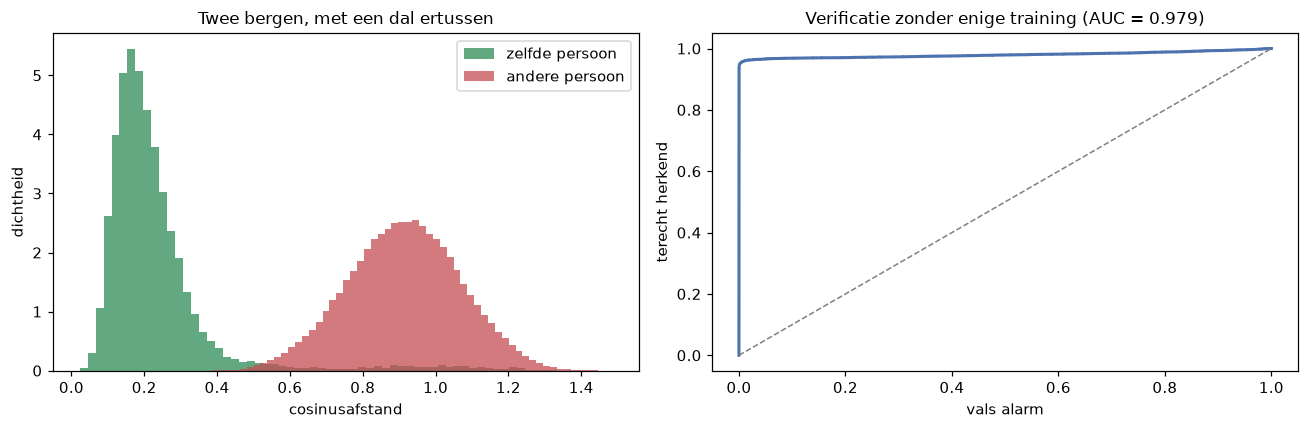

Merk op: we hebben nog NIETS getraind. Dit is puur wat FaceNet meebrengt.


In [10]:
fig, (a, b) = plt.subplots(1, 2, figsize=(12, 4))

a.hist(paar_afstand[zelfde_persoon], bins=60, alpha=0.75, density=True,
       color="#2E8B57", label="zelfde persoon")
a.hist(paar_afstand[~zelfde_persoon], bins=60, alpha=0.75, density=True,
       color="#C44E52", label="andere persoon")
a.set_xlabel("cosinusafstand"); a.set_ylabel("dichtheid")
a.set_title("Twee bergen, met een dal ertussen", fontsize=11)
a.legend()

# Waar zou je de grens leggen? Elke drempel is een afweging.
fpr, tpr, drempels = roc_curve(zelfde_persoon, -paar_afstand)
auc = roc_auc_score(zelfde_persoon, -paar_afstand)
b.plot(fpr, tpr, lw=2, color="#4C72B0"); b.plot([0, 1], [0, 1], "--", color="grey", lw=1)
b.set_xlabel("vals alarm"); b.set_ylabel("terecht herkend")
b.set_title(f"Verificatie zonder enige training (AUC = {auc:.3f})", fontsize=11)

plt.tight_layout()
plt.show()

print("Merk op: we hebben nog NIETS getraind. Dit is puur wat FaceNet meebrengt.")

### Hetzelfde, maar dan om naar te kijken

512 dimensies kun je niet tekenen. Met PCA duwen we ze plat naar twee, en dan zie je waar het
in de praktijk op neerkomt: **foto's van dezelfde persoon klonteren samen.**

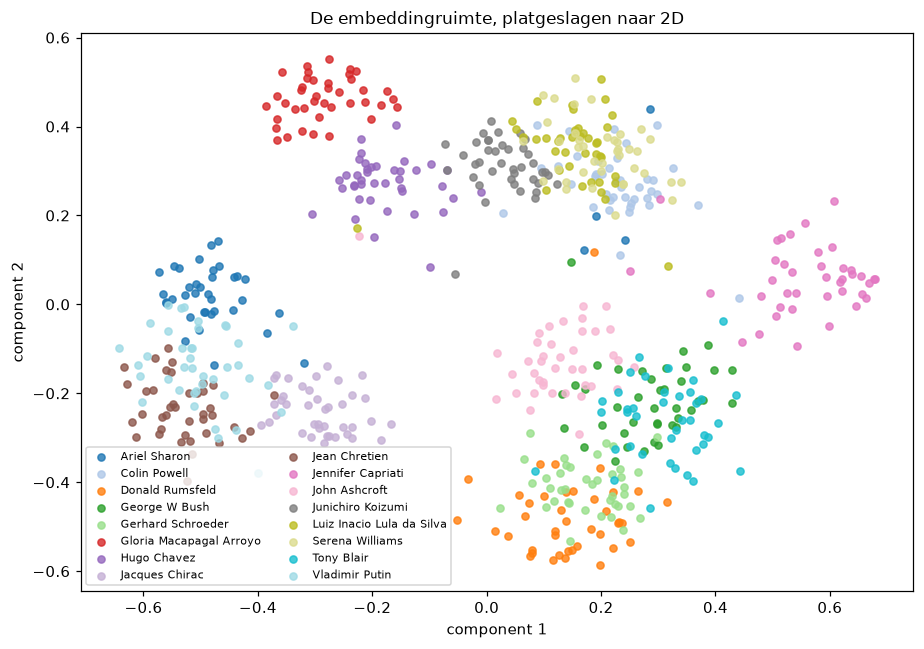

Wat je hier ziet is maar een schaduw: twee van de 512 richtingen.
Dat de groepjes dan nog steeds zichtbaar zijn, zegt hoe sterk het signaal is.


In [11]:
plat = PCA(n_components=2, random_state=RANDOM_STATE).fit_transform(embeddings)

fig, ax = plt.subplots(figsize=(8.5, 6))
kleuren = plt.cm.tab20(np.linspace(0, 1, len(personen)))
for kleur, persoon in zip(kleuren, personen):
    m = labels == persoon
    ax.scatter(plat[m, 0], plat[m, 1], s=22, color=kleur, label=persoon, alpha=0.8)
ax.set_title("De embeddingruimte, platgeslagen naar 2D", fontsize=11)
ax.set_xlabel("component 1"); ax.set_ylabel("component 2")
ax.legend(fontsize=7, ncol=2, loc="best")
plt.tight_layout()
plt.show()

print("Wat je hier ziet is maar een schaduw: twee van de 512 richtingen.")
print("Dat de groepjes dan nog steeds zichtbaar zijn, zegt hoe sterk het signaal is.")

---

## 5. Ons eigen model: wie is dit?

FaceNet geeft ons getallen, geen namen. Het weet niet wie George W. Bush is en dat hoeft ook
niet — **dat stukje bouwen we zelf**, en het is verrassend klein.

Ons model krijgt 512 getallen binnen en moet één van de 16 namen kiezen. Dat is gewoon een
classificatieprobleem, en daar is een paar lagen Keras genoeg voor.

In [12]:
# Namen omzetten naar nummers, want daar rekent het model mee.
naam_naar_nummer = {naam: i for i, naam in enumerate(personen)}
y = np.array([naam_naar_nummer[n] for n in labels])

# Per persoon 70% voor training, 30% om te testen. Stratified, zodat iedereen
# in beide helften zit.
is_train = np.zeros(len(y), dtype=bool)
for klasse in range(len(personen)):
    rijen = np.where(y == klasse)[0]
    is_train[rng.choice(rijen, int(0.7 * len(rijen)), replace=False)] = True

X_train, y_train = embeddings[is_train],  y[is_train]
X_test,  y_test  = embeddings[~is_train], y[~is_train]

print(f"train: {len(X_train)} gezichten")
print(f"test : {len(X_test)} gezichten")

train: 448 gezichten
test : 192 gezichten


In [13]:
def maak_classifier(aantal_personen, dim_in=512):
    return keras.Sequential(
        [
            keras.Input(shape=(dim_in,), name="embedding"),
            layers.Dense(128, activation="relu", name="verborgen"),
            layers.Dropout(0.3, name="dropout"),
            layers.Dense(aantal_personen, activation="softmax", name="wie"),
        ],
        name="gezichtsclassifier",
    )


keras.utils.set_random_seed(RANDOM_STATE)
classifier = maak_classifier(len(personen))
classifier.compile(
    optimizer=keras.optimizers.Adam(1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)
classifier.summary()

Model: "gezichtsclassifier"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ verborgen (Dense)               │ (None, 128)            │        65,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ wie (Dense)                     │ (None, 16)             │         2,064 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 67,728 (264.56 KB)

 Trainable params: 67,728 (264.56 KB)

 Non-trainable params: 0 (0.00 B)

test-accuracy: 97.9%  op 192 gezichten


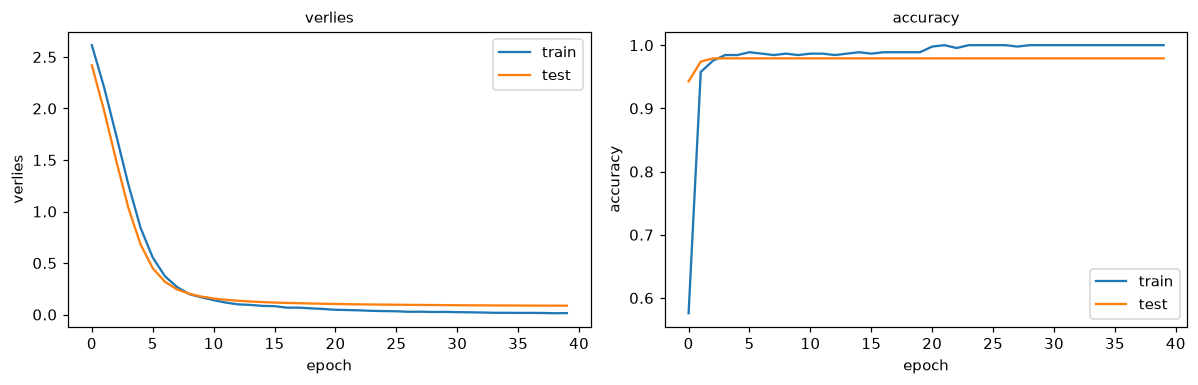

In [14]:
historie = classifier.fit(
    X_train, y_train,
    validation_data=(X_test, y_test),
    epochs=40, batch_size=32, verbose=0,
)

verlies, accuratesse = classifier.evaluate(X_test, y_test, verbose=0)
print(f"test-accuracy: {accuratesse:.1%}  op {len(X_test)} gezichten")

fig, (a, b) = plt.subplots(1, 2, figsize=(11, 3.6))
a.plot(historie.history["loss"], label="train"); a.plot(historie.history["val_loss"], label="test")
a.set_xlabel("epoch"); a.set_ylabel("verlies"); a.legend(); a.set_title("verlies", fontsize=10)
b.plot(historie.history["accuracy"], label="train"); b.plot(historie.history["val_accuracy"], label="test")
b.set_xlabel("epoch"); b.set_ylabel("accuracy"); b.legend(); b.set_title("accuracy", fontsize=10)
plt.tight_layout()
plt.show()

### Hoeveel foto's heb je eigenlijk nodig?

Dit is het moment waarop transfer learning echt indruk maakt. We trainen hetzelfde model
opnieuw, maar met steeds minder foto's per persoon.

   1 foto's per persoon  ->  accuracy 91.8%
   2 foto's per persoon  ->  accuracy 98.2%
   3 foto's per persoon  ->  accuracy 98.3%
   5 foto's per persoon  ->  accuracy 98.8%
  10 foto's per persoon  ->  accuracy 97.9%
  20 foto's per persoon  ->  accuracy 99.7%


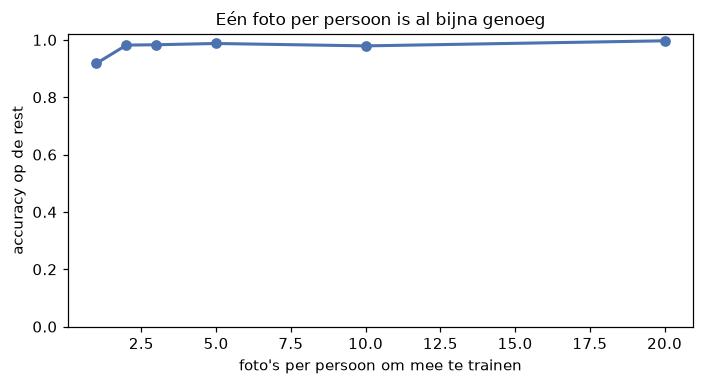

In [15]:
resultaten = []
for k in [1, 2, 3, 5, 10, 20]:
    kleine_train = np.zeros(len(y), dtype=bool)
    r = np.random.default_rng(RANDOM_STATE)
    for klasse in range(len(personen)):
        rijen = np.where(y == klasse)[0]
        kleine_train[r.choice(rijen, k, replace=False)] = True

    keras.utils.set_random_seed(RANDOM_STATE)
    mini = maak_classifier(len(personen))
    mini.compile(optimizer=keras.optimizers.Adam(1e-3),
                 loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    mini.fit(embeddings[kleine_train], y[kleine_train],
             epochs=60, batch_size=16, verbose=0)
    acc = mini.evaluate(embeddings[~kleine_train], y[~kleine_train], verbose=0)[1]
    resultaten.append((k, acc))
    print(f"  {k:2d} foto's per persoon  ->  accuracy {acc:.1%}")

fig, ax = plt.subplots(figsize=(6.5, 3.6))
ks, accs = zip(*resultaten)
ax.plot(ks, accs, "o-", lw=2, color="#4C72B0")
ax.set_xlabel("foto's per persoon om mee te trainen")
ax.set_ylabel("accuracy op de rest")
ax.set_ylim(0, 1.02)
ax.set_title("Eén foto per persoon is al bijna genoeg", fontsize=11)
plt.tight_layout()
plt.show()

**Dat is het punt van transfer learning.** Met één foto per persoon zit je al boven de 90%,
en met twee foto's boven de 98%.
Niet omdat ons modelletje zo slim is — het heeft nog geen 70.000 parameters — maar omdat
FaceNet het zware werk al gedaan heeft. Wij hoeven alleen nog de namen erbij te plakken.

Probeer datzelfde eens met één foto per persoon en een netwerk dat vanaf nul moet beginnen.

---

### Eerst een eerlijke testopstelling

Vanaf hier gaan we zelf modellen trainen die met **paren** werken. Om te weten of zoiets echt
iets leert, moeten we twee vragen los van elkaar kunnen beantwoorden:

1. Wordt het beter voor **de mensen die het gezien heeft**? (een bedrijf dat zijn eigen
   medewerkers herkent)
2. Wordt het beter voor **volslagen onbekenden**? (een systeem dat op iedereen moet werken)

Daarom zetten we vier personen helemaal apart. Die komen in geen enkele trainingsstap voor.

In [16]:
apart = np.random.default_rng(7)
geschud = personen.copy(); apart.shuffle(geschud)
ONGEZIEN = sorted(geschud[:4])           # deze vier houden we volledig buiten
BEKEND   = sorted(geschud[4:])

is_ongezien = np.isin(labels, ONGEZIEN)

# Waar we op trainen: trainfoto's van de bekende personen.
train_paar = is_train & ~is_ongezien

print("bekend (trainen + testen):")
print("  " + ", ".join(BEKEND))
print("\nongezien (alleen testen):")
print("  " + ", ".join(ONGEZIEN))
print(f"\nfoto's om paren uit te maken : {train_paar.sum()}")
print(f"testfoto's bekende personen  : {(~is_train & ~is_ongezien).sum()}")
print(f"foto's ongeziene personen    : {is_ongezien.sum()}")

bekend (trainen + testen):
  Ariel Sharon, Colin Powell, Donald Rumsfeld, Gerhard Schroeder, Gloria Macapagal Arroyo, Jacques Chirac, Jennifer Capriati, Junichiro Koizumi, Luiz Inacio Lula da Silva, Serena Williams, Tony Blair, Vladimir Putin

ongezien (alleen testen):
  George W Bush, Hugo Chavez, Jean Chretien, John Ashcroft

foto's om paren uit te maken : 336
testfoto's bekende personen  : 144
foto's ongeziene personen    : 160


In [17]:
# Eén functie die we voor elke aanpak opnieuw gebruiken, zodat de vergelijking eerlijk blijft.
def verificatie_auc(scorefunctie, masker):
    # scorefunctie(a, b) -> hoe hoger, hoe waarschijnlijker dezelfde persoon
    E_deel, L_deel = embeddings[masker], labels[masker]
    boven = np.triu_indices(len(E_deel), k=1)
    a, b = E_deel[boven[0]], E_deel[boven[1]]
    zelfde = (L_deel[boven[0]] == L_deel[boven[1]]).astype(int)
    return roc_auc_score(zelfde, scorefunctie(a, b)), zelfde

# De maat zonder enige training: gewoon de cosinus tussen twee FaceNet-vectoren.
cosinus = lambda a, b: np.sum(a * b, axis=1)

auc_cos_bekend, zelfde_bekend = verificatie_auc(cosinus, ~is_train & ~is_ongezien)
auc_cos_ongezien, zelfde_ongezien = verificatie_auc(cosinus, is_ongezien)

print(f"FaceNet + cosinus, zonder training:")
print(f"  bekende personen  : AUC {auc_cos_bekend:.4f}")
print(f"  ongeziene personen: AUC {auc_cos_ongezien:.4f}")
print("\nDat zijn de twee getallen die we proberen te verslaan.")

FaceNet + cosinus, zonder training:
  bekende personen  : AUC 0.9722
  ongeziene personen: AUC 0.9785

Dat zijn de twee getallen die we proberen te verslaan.


## 6. Contrastive learning: het zelf beter maken

Tot hier hebben we de embeddings van FaceNet gebruikt zoals ze zijn. Nu gaan we ze
**aanpassen aan onze eigen mensen** — en daarvoor gebruiken we het idee waarmee FaceNet zelf
getraind is.

### Het idee: leer van vergelijkingen, niet van labels

Een gewone classifier leert "deze foto hoort bij klasse 7". Contrastive learning leert iets
anders:

> *"Deze twee horen bij elkaar. Die derde niet. Zorg dat je ruimte dat weerspiegelt."*

Je hebt er dus geen namen voor nodig, alleen het besef welke dingen bij elkaar horen. Daarom
werkt het ook op enorme hoeveelheden data zonder labels — en daarom zie je het overal terug,
van beeldherkenning tot taalmodellen.

### Triplet loss

De concrete vorm die FaceNet gebruikt, werkt met **drie** foto's tegelijk:

| | | |
|---|---|---|
| **anker** | een foto van persoon A | het vertrekpunt |
| **positief** | een *andere* foto van persoon A | moet dichterbij komen |
| **negatief** | een foto van persoon B | moet verder weg |

Het model wordt beloond als de afstand tot het positieve voorbeeld **kleiner** is dan de
afstand tot het negatieve, met een veiligheidsmarge ertussen. Zit het al goed, dan is er niets
te leren en is het verlies nul.

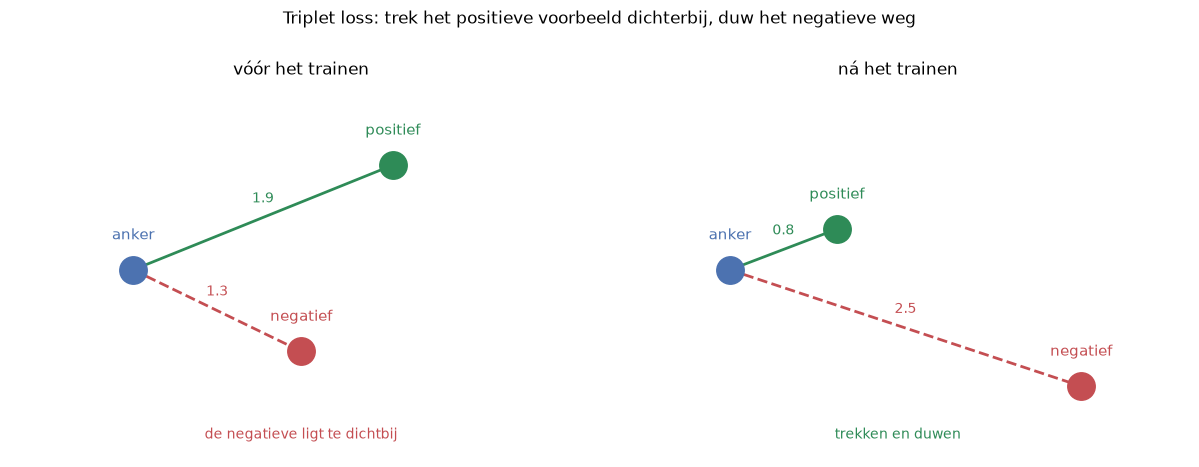

In [18]:
# De tekening die erbij hoort: voor en na.
fig, (voor, na) = plt.subplots(1, 2, figsize=(11, 4.2))

posities = {
    "voor": {"anker": (0, 0), "positief": (1.7, 0.9), "negatief": (1.1, -0.7)},
    "na":   {"anker": (0, 0), "positief": (0.7, 0.35), "negatief": (2.3, -1.0)},
}

for ax, sleutel, titel in [(voor, "voor", "vóór het trainen"), (na, "na", "ná het trainen")]:
    p = posities[sleutel]
    for naam_punt, kleur in [("anker", "#4C72B0"), ("positief", "#2E8B57"), ("negatief", "#C44E52")]:
        ax.scatter(*p[naam_punt], s=320, color=kleur, zorder=3)
        ax.annotate(naam_punt, p[naam_punt], textcoords="offset points",
                    xytext=(0, 20), ha="center", fontsize=10, color=kleur)

    for doel, kleur, stijl in [("positief", "#2E8B57", "-"), ("negatief", "#C44E52", "--")]:
        ax.plot([p["anker"][0], p[doel][0]], [p["anker"][1], p[doel][1]],
                stijl, color=kleur, lw=1.8, zorder=1)
        afstand = np.hypot(p[doel][0] - p["anker"][0], p[doel][1] - p["anker"][1])
        ax.text((p["anker"][0] + p[doel][0]) / 2, (p["anker"][1] + p[doel][1]) / 2 + 0.13,
                f"{afstand:.1f}", color=kleur, fontsize=9, ha="center")

    ax.set_xlim(-0.8, 3.0); ax.set_ylim(-1.6, 1.6)
    ax.set_title(titel, fontsize=11); ax.axis("off")

voor.text(1.1, -1.45, "de negatieve ligt te dichtbij", fontsize=9, color="#C44E52", ha="center")
na.text(1.1, -1.45, "trekken en duwen", fontsize=9, color="#2E8B57", ha="center")
fig.suptitle("Triplet loss: trek het positieve voorbeeld dichterbij, duw het negatieve weg",
             fontsize=11, y=1.0)
plt.tight_layout()
plt.show()

### De verliesfunctie zelf schrijven

Keras heeft hier geen kant-en-klare laag voor, dus we schrijven hem. Dat valt mee: het is
letterlijk de zin van hierboven, in code.

We gebruiken `keras.ops` in plaats van numpy, zodat de functie met de rekengrafiek meekan.

In [19]:
def triplet_verlies(marge=0.3):
    # y_pred bevat de drie embeddings achter elkaar geplakt: [anker | positief | negatief]
    def verlies(y_true, y_pred):
        d = y_pred.shape[-1] // 3
        anker     = y_pred[:, :d]
        positief  = y_pred[:, d:2 * d]
        negatief  = y_pred[:, 2 * d:]

        afstand_positief = ops.sum(ops.square(anker - positief), axis=1)
        afstand_negatief = ops.sum(ops.square(anker - negatief), axis=1)

        # We willen: positief + marge < negatief.
        # Is dat al zo, dan is het verlies 0 en valt er niets te leren.
        return ops.maximum(afstand_positief - afstand_negatief + marge, 0.0)

    return verlies

### Het model: één hoofd, drie ingangen

Hier zit de elegantie van een siamees netwerk. We bouwen **één** klein netwerk — het
*projectiehoofd* — en sturen alle drie de foto's er doorheen. Dezelfde gewichten, drie keer
gebruikt.

Het hoofd perst de 512 getallen van FaceNet samen tot 64, en normaliseert die weer naar
lengte 1 zodat we dezelfde afstandsmaat kunnen blijven gebruiken.

In [20]:
def maak_projectiehoofd(dim_in=512, dim_uit=64):
    return keras.Sequential(
        [
            keras.Input(shape=(dim_in,), name="facenet_embedding"),
            layers.Dense(256, activation="relu", name="verborgen"),
            layers.Dense(dim_uit, name="projectie"),
            layers.UnitNormalization(name="op_de_bol"),   # terug naar lengte 1
        ],
        name="projectiehoofd",
    )


keras.utils.set_random_seed(RANDOM_STATE)
hoofd = maak_projectiehoofd()

# Drie ingangen, één gedeeld hoofd -> een siamees netwerk.
in_anker    = keras.Input(shape=(512,), name="anker")
in_positief = keras.Input(shape=(512,), name="positief")
in_negatief = keras.Input(shape=(512,), name="negatief")

drieluik = layers.Concatenate(name="aan_elkaar")(
    [hoofd(in_anker), hoofd(in_positief), hoofd(in_negatief)]
)

triplet_model = keras.Model([in_anker, in_positief, in_negatief], drieluik,
                            name="triplet_netwerk")
triplet_model.compile(optimizer=keras.optimizers.Adam(1e-3), loss=triplet_verlies(marge=0.3))

hoofd.summary()
print(f"\nHet hoofd heeft {hoofd.count_params():,} parameters en wordt drie keer gebruikt.")

Model: "projectiehoofd"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ verborgen (Dense)               │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ projectie (Dense)               │ (None, 64)             │        16,448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ op_de_bol (UnitNormalization)   │ (None, 64)             │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 147,776 (577.25 KB)

 Trainable params: 147,776 (577.25 KB)

 Non-trainable params: 0 (0.00 B)


Het hoofd heeft 147,776 parameters en wordt drie keer gebruikt.


20,000 triplets gemaakt uit 336 foto's van 12 personen


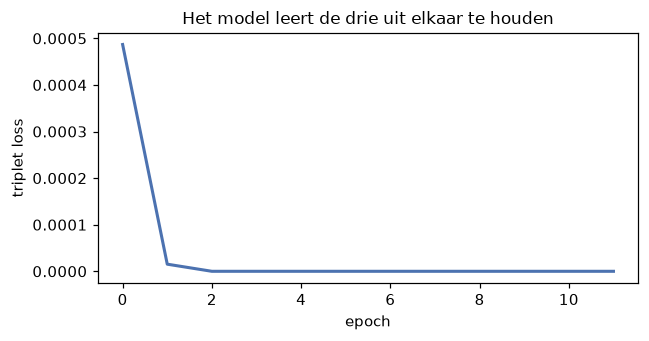

In [21]:
def maak_triplets(emb, lab, aantal, rng):
    # Trek telkens: twee foto's van dezelfde persoon + één van iemand anders.
    per_persoon = {p: np.where(lab == p)[0] for p in set(lab)}
    wie = list(per_persoon)

    ankers, positieven, negatieven = [], [], []
    for _ in range(aantal):
        a = rng.choice(wie)
        b = rng.choice([w for w in wie if w != a])
        i, j = rng.choice(per_persoon[a], 2, replace=False)
        k    = rng.choice(per_persoon[b])
        ankers.append(emb[i]); positieven.append(emb[j]); negatieven.append(emb[k])

    return np.array(ankers), np.array(positieven), np.array(negatieven)


# BELANGRIJK: alleen trainfoto's van de BEKENDE personen. De testfoto's en de
# vier ongeziene personen blijven volledig buiten beeld.
A, P, N = maak_triplets(embeddings[train_paar], labels[train_paar], 20_000,
                        np.random.default_rng(RANDOM_STATE))
print(f"{len(A):,} triplets gemaakt uit {train_paar.sum()} foto's van {len(BEKEND)} personen")

# y is een dummy: onze verliesfunctie gebruikt hem niet.
geschiedenis = triplet_model.fit([A, P, N], np.zeros(len(A)),
                                 epochs=12, batch_size=128, verbose=0)

fig, ax = plt.subplots(figsize=(6, 3.2))
ax.plot(geschiedenis.history["loss"], lw=2, color="#4C72B0")
ax.set_xlabel("epoch"); ax.set_ylabel("triplet loss")
ax.set_title("Het model leert de drie uit elkaar te houden", fontsize=11)
plt.tight_layout()
plt.show()

### Heeft het geholpen?

De eerlijke test: we vergelijken verificatie op de **testfoto's**, die het projectiehoofd nooit
gezien heeft. Zijn de twee bergen uit §4 verder uit elkaar geschoven?

In [22]:
# Het hoofd projecteert 512 -> 64; daarna is de cosinus weer de maat.
def score_hoofd(a, b):
    return np.sum(hoofd.predict(a, verbose=0) * hoofd.predict(b, verbose=0), axis=1)

auc_trip_bekend, _   = verificatie_auc(score_hoofd, ~is_train & ~is_ongezien)
auc_trip_ongezien, _ = verificatie_auc(score_hoofd, is_ongezien)

print(f"bekende personen  : AUC {auc_trip_bekend:.4f}   (cosinus was {auc_cos_bekend:.4f})")
print(f"ongeziene personen: AUC {auc_trip_ongezien:.4f}   (cosinus was {auc_cos_ongezien:.4f})")
print()
print(f"En dat met {512 // 64}x minder getallen per gezicht.")

bekende personen  : AUC 0.9851   (cosinus was 0.9722)
ongeziene personen: AUC 0.9878   (cosinus was 0.9785)

En dat met 8x minder getallen per gezicht.


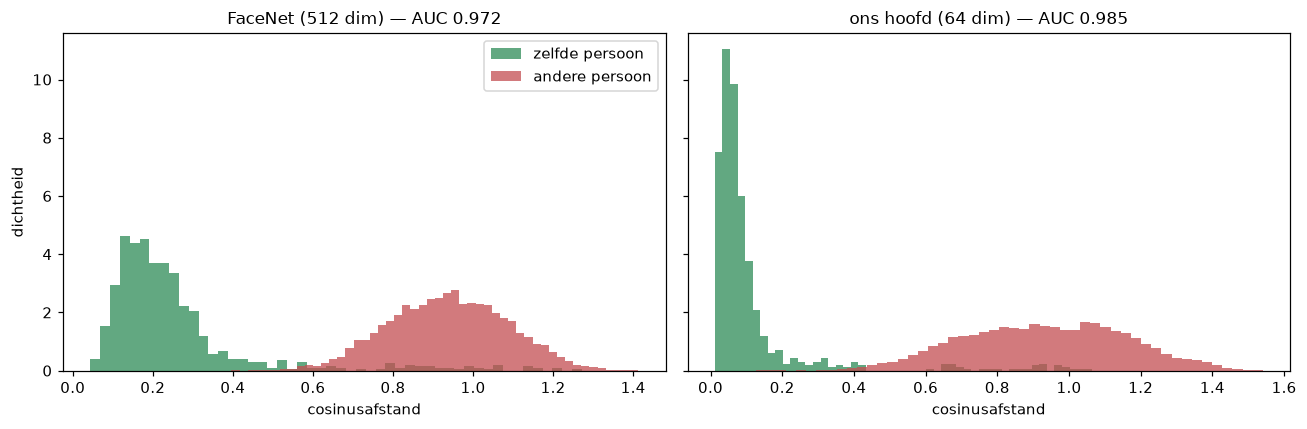

In [23]:
# De twee bergen uit paragraaf 4, voor en na.
def afstanden_van(scorefunctie, masker):
    E_deel, L_deel = embeddings[masker], labels[masker]
    boven = np.triu_indices(len(E_deel), k=1)
    s = scorefunctie(E_deel[boven[0]], E_deel[boven[1]])
    return 1 - s, (L_deel[boven[0]] == L_deel[boven[1]])

masker_bekend = ~is_train & ~is_ongezien
d_voor, zelfde_b = afstanden_van(cosinus, masker_bekend)
d_na, _ = afstanden_van(score_hoofd, masker_bekend)

fig, (a, b) = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, d, titel, auc_w in [(a, d_voor, "FaceNet (512 dim)", auc_cos_bekend),
                            (b, d_na, "ons hoofd (64 dim)", auc_trip_bekend)]:
    ax.hist(d[zelfde_b], bins=50, alpha=0.75, density=True, color="#2E8B57",
            label="zelfde persoon")
    ax.hist(d[~zelfde_b], bins=50, alpha=0.75, density=True, color="#C44E52",
            label="andere persoon")
    ax.set_xlabel("cosinusafstand"); ax.set_title(f"{titel} — AUC {auc_w:.3f}", fontsize=11)
a.set_ylabel("dichtheid"); a.legend()
plt.tight_layout()
plt.show()

### Wat je hier wel en niet mag concluderen

Het hoofd maakt de scheiding **scherper voor de mensen die het kent**, en doet dat in 64 in
plaats van 512 getallen. Dat is precies waar zo'n hoofd voor is: een bedrijf dat zijn eigen
honderd medewerkers wil herkennen, haalt hier winst.

Maar er hoort een eerlijke waarschuwing bij. Laat je dit hoofd los op **volstrekt onbekende
gezichten** — mensen die niet in de trainingsfoto's zaten — dan verslaat het FaceNet niet.
Dat is ook niet zo gek:

> FaceNet ís een contrastive model. Het is met precies deze verliesfunctie getraind, op
> miljoenen gezichten. Wij trainen met dezelfde techniek op een paar honderd foto's van
> twaalf mensen. Dat maakt ons niet beter in "gezichten in het algemeen" — het maakt ons
> beter in *deze* mensen.

Dat is geen tegenvaller maar de kern van de afweging: **specialiseren kost algemeenheid.**

Blijft één vraag hangen: we hebben de meetlat al die tijd vast laten staan en alleen de ruimte
verbouwd. Wat als we het omdraaien?

---

## 7. Een ander idee: laat het model de vergelijking zélf leren

Bij triplet loss houden we de **meetlat vast** (cosinusafstand) en verbouwen we de ruimte.
Je kunt het ook precies omdraaien: laat de embeddings zoals ze zijn, en train een model dat
twee vectoren binnenkrijgt en zegt *"zelfde persoon: ja of nee"*.

Dat klinkt misschien als vals spelen, maar het is een erkende techniek — een **learned metric**
of verificatienetwerk. De klassieke Siamese one-shot-paper van Koch (2015) doet precies dit.

### Hoe voer je twee vectoren in één netwerk?

Niet door ze simpelweg achter elkaar te plakken. Dan leert het model dat "a links, b rechts"
iets anders is dan "b links, a rechts", terwijl dat dezelfde vraag is. We geven het netwerk
daarom twee combinaties die **symmetrisch** zijn:

| | | waarom |
|---|---|---|
| `\|a - b\|` | het verschil per getal | waar wijken de twee gezichten af? |
| `a * b` | het product per getal | waar zijn ze het juist eens? |

Samen 1024 getallen, en of je nu `(a, b)` of `(b, a)` invoert maakt niets uit.

In [24]:
def maak_vergelijker(dim=512):
    gezicht_a = keras.Input(shape=(dim,), name="gezicht_a")
    gezicht_b = keras.Input(shape=(dim,), name="gezicht_b")

    # Twee symmetrische manieren om de vectoren te combineren.
    verschil = layers.Lambda(lambda t: ops.abs(t), name="absoluut_verschil")(
        layers.Subtract(name="verschil")([gezicht_a, gezicht_b]))
    product = layers.Multiply(name="product")([gezicht_a, gezicht_b])
    samen = layers.Concatenate(name="samen")([verschil, product])

    x = layers.Dense(128, activation="relu", name="verborgen1")(samen)
    x = layers.Dropout(0.3, name="dropout")(x)
    x = layers.Dense(64, activation="relu", name="verborgen2")(x)
    oordeel = layers.Dense(1, activation="sigmoid", name="zelfde_persoon")(x)

    return keras.Model([gezicht_a, gezicht_b], oordeel, name="vergelijker")


keras.utils.set_random_seed(RANDOM_STATE)
vergelijker = maak_vergelijker()
vergelijker.compile(optimizer=keras.optimizers.Adam(1e-3),
                    loss="binary_crossentropy", metrics=["accuracy"])
vergelijker.summary(line_length=88)

Model: "vergelijker"

┏━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)            ┃ Output Shape         ┃      Param # ┃ Connected to         ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━┩
│ gezicht_a (InputLayer)  │ (None, 512)          │            0 │ -                    │
├─────────────────────────┼──────────────────────┼──────────────┼──────────────────────┤
│ gezicht_b (InputLayer)  │ (None, 512)          │            0 │ -                    │
├─────────────────────────┼──────────────────────┼──────────────┼──────────────────────┤
│ verschil (Subtract)     │ (None, 512)          │            0 │ gezicht_a[0][0],     │
│                         │                      │              │ gezicht_b[0][0]      │
├─────────────────────────┼──────────────────────┼──────────────┼──────────────────────┤
│ absoluut_verschil       │ (None, 512)          │            0 │ verschil[0][0]       │
│ (Lambda)                │                      │              │                      │
├─────────────────────────┼──────────────────────┼──────────────┼──────────────────────┤
│ product (Multiply)      │ (None, 512)          │            0 │ gezicht_a[0][0],     │
│                         │                      │              │ gezicht_b[0][0]      │
├─────────────────────────┼──────────────────────┼──────────────┼──────────────────────┤
│ samen (Concatenate)     │ (None, 1024)         │            0 │ absoluut_verschil[0… │
│                         │                      │              │ product[0][0]        │
├─────────────────────────┼──────────────────────┼──────────────┼──────────────────────┤
│ verborgen1 (Dense)      │ (None, 128)          │      131,200 │ samen[0][0]          │
├─────────────────────────┼──────────────────────┼──────────────┼──────────────────────┤
│ dropout (Dropout)       │ (None, 128)          │            0 │ verborgen1[0][0]     │
├─────────────────────────┼──────────────────────┼──────────────┼──────────────────────┤
│ verborgen2 (Dense)      │ (None, 64)           │        8,256 │ dropout[0][0]        │
├─────────────────────────┼──────────────────────┼──────────────┼──────────────────────┤
│ zelfde_persoon (Dense)  │ (None, 1)            │           65 │ verborgen2[0][0]     │
└─────────────────────────┴──────────────────────┴──────────────┴──────────────────────┘

 Total params: 139,521 (545.00 KB)

 Trainable params: 139,521 (545.00 KB)

 Non-trainable params: 0 (0.00 B)

40,000 paren: 20,000 zelfde persoon, 20,000 verschillende


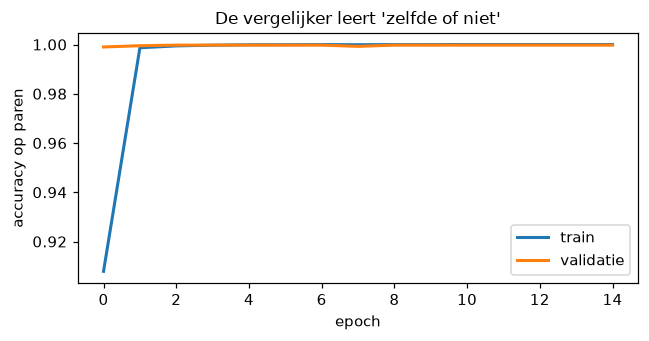

In [25]:
def maak_paren(emb, lab, aantal, rng):
    # Evenveel 'zelfde persoon' als 'andere persoon', anders leert het model
    # gewoon altijd 'nee' te zeggen: dat klopt in 95% van de willekeurige paren.
    per_persoon = {p: np.where(lab == p)[0] for p in set(lab)}
    wie = list(per_persoon)

    links, rechts, doel = [], [], []
    for _ in range(aantal // 2):
        a = rng.choice(wie)
        i, j = rng.choice(per_persoon[a], 2, replace=False)
        links.append(emb[i]); rechts.append(emb[j]); doel.append(1)

        b = rng.choice([w for w in wie if w != a])
        m, k = rng.choice(per_persoon[a]), rng.choice(per_persoon[b])
        links.append(emb[m]); rechts.append(emb[k]); doel.append(0)

    return np.array(links), np.array(rechts), np.array(doel, dtype="float32")


L_paar, R_paar, Y_paar = maak_paren(
    embeddings[train_paar], labels[train_paar], 40_000, np.random.default_rng(RANDOM_STATE))
print(f"{len(L_paar):,} paren: {int(Y_paar.sum()):,} zelfde persoon, "
      f"{int((1 - Y_paar).sum()):,} verschillende")

historie_paar = vergelijker.fit([L_paar, R_paar], Y_paar,
                                epochs=15, batch_size=256, validation_split=0.1, verbose=0)

fig, ax = plt.subplots(figsize=(6, 3.2))
ax.plot(historie_paar.history["accuracy"], lw=2, label="train")
ax.plot(historie_paar.history["val_accuracy"], lw=2, label="validatie")
ax.set_xlabel("epoch"); ax.set_ylabel("accuracy op paren"); ax.legend()
ax.set_title("De vergelijker leert 'zelfde of niet'", fontsize=11)
plt.tight_layout()
plt.show()

In [26]:
# De uitvoer van het netwerk is nu zelf de score.
def score_vergelijker(a, b):
    return vergelijker.predict([a, b], verbose=0, batch_size=4096).ravel()

auc_paar_bekend, _   = verificatie_auc(score_vergelijker, ~is_train & ~is_ongezien)
auc_paar_ongezien, _ = verificatie_auc(score_vergelijker, is_ongezien)

print(f"bekende personen  : AUC {auc_paar_bekend:.4f}   (cosinus was {auc_cos_bekend:.4f})")
print(f"ongeziene personen: AUC {auc_paar_ongezien:.4f}   (cosinus was {auc_cos_ongezien:.4f})")

bekende personen  : AUC 0.9931   (cosinus was 0.9722)
ongeziene personen: AUC 0.9903   (cosinus was 0.9785)


In [27]:
overzicht = pd.DataFrame([
    {"aanpak": "FaceNet + cosinus (niets getraind)",
     "bekende personen": auc_cos_bekend,  "ongeziene personen": auc_cos_ongezien,
     "snel doorzoekbaar": "ja"},
    {"aanpak": "ons projectiehoofd (triplet loss)",
     "bekende personen": auc_trip_bekend, "ongeziene personen": auc_trip_ongezien,
     "snel doorzoekbaar": "ja"},
    {"aanpak": "onze vergelijker (pairwise MLP)",
     "bekende personen": auc_paar_bekend, "ongeziene personen": auc_paar_ongezien,
     "snel doorzoekbaar": "nee"},
]).set_index("aanpak").round(4)

display(overzicht)

,bekende personen,ongeziene personen,snel doorzoekbaar
aanpak,,,
FaceNet + cosinus (niets getraind),0.9722,0.9785,ja
ons projectiehoofd (triplet loss),0.9851,0.9878,ja
onze vergelijker (pairwise MLP),0.9931,0.9903,nee


### De afweging waar het echt om gaat

Kijk niet alleen naar de AUC-kolommen, maar vooral naar de laatste.

**Triplet loss verbouwt de ruimte.** Daarna is vergelijken nog steeds één
matrixvermenigvuldiging. Je kunt een miljoen gezichten in een vectordatabase zetten en in
milliseconden de dichtstbijzijnde vinden. Alle embeddings kun je vooraf uitrekenen en opslaan.

**De vergelijker leert de meetlat zelf.** Dat is expressiever — hij kan verbanden tussen
losse getallen oppikken die een vaste afstandsmaat nooit ziet — maar je betaalt een prijs:
er ís geen afstand meer die je vooraf kunt uitrekenen. Wil je één gezicht tegen een miljoen
andere houden, dan moet het netwerk een miljoen keer draaien.

| | triplet-hoofd | pairwise vergelijker |
|---|---|---|
| Wat leert het? | een betere **ruimte** | een betere **vergelijking** |
| Zoeken in een grote database | snel (vectorindex) | traag (N keer het model draaien) |
| Embedding vooraf opslaan | ja | ja, maar de vergelijking niet |
| Expressiviteit | beperkt tot een afstandsmaat | vrij |
| Typisch gebruikt voor | zoeken, clusteren, aanbevelen | één-op-één verifiëren |

**Praktijkregel:** moet je zoeken in een grote verzameling, dan wil je een embedding en dus
triplet loss. Moet je twee dingen vergelijken die je toch al in handen hebt — een selfie tegen
de pasfoto op je identiteitskaart — dan is een vergelijker prima, en vaak beter.

## 8. Je eigen foto

Nu het leuke deel. De hele pijplijn staat er: detecteren, embedden, herkennen.

**Zo doe je het:**

1. Maak in `data/mijn-gezichten/` een map met jouw naam, bijvoorbeeld `data/mijn-gezichten/Kristof/`.
2. Sleep er een stuk of vijf foto's van jezelf in (gewone JPEG's, gezicht duidelijk in beeld).
3. Wil je het spannender maken: voeg ook een map van een huisgenoot of een collega toe.
4. Draai de cellen hieronder opnieuw.

Werkt ook zonder eigen foto's — dan doet de notebook alsof een testfoto je upload is.

In [28]:
EIGEN = Path("data/mijn-gezichten")
eigen_paden = sorted([p for p in EIGEN.rglob("*") if p.suffix.lower() in {".jpg", ".jpeg", ".png"}]) if EIGEN.exists() else []

if eigen_paden:
    print(f"{len(eigen_paden)} eigen foto's gevonden:")
    for p in eigen_paden:
        print(f"   {p.parent.name:20s} {p.name}")
else:
    print("Nog geen eigen foto's gevonden in data/mijn-gezichten/.")
    print("Geen probleem: we gebruiken hieronder een testfoto alsof jij hem net geüpload hebt.")

Nog geen eigen foto's gevonden in data/mijn-gezichten/.
Geen probleem: we gebruiken hieronder een testfoto alsof jij hem net geüpload hebt.


In [29]:
# De volledige pijplijn in één functie: van bestand naar naam.
def herken(pad_of_array, top=3):
    if isinstance(pad_of_array, (str, Path)):
        foto = np.array(Image.open(pad_of_array).convert("RGB"))
    else:
        foto = pad_of_array

    # 1. gezicht vinden
    kandidaten = detector.detect_faces(foto)
    if not kandidaten:
        return None, None, "geen gezicht gevonden"

    beste = max(kandidaten, key=lambda d: d["confidence"])
    x, y_, w, h = beste["box"]
    dx, dy = int(w * 0.15), int(h * 0.15)
    x, y_ = max(0, x - dx), max(0, y_ - dy)
    uitsnede = np.array(Image.fromarray(foto[y_:y_ + h + 2 * dy, x:x + w + 2 * dx]).resize((160, 160)))

    # 2. embedding maken
    vector = embedder.embeddings(uitsnede[None, ...])

    # 3. ons eigen model laten kiezen
    kansen = classifier.predict(vector, verbose=0)[0]
    beste_n = np.argsort(kansen)[::-1][:top]

    return foto, (uitsnede, beste), [(personen[n], float(kansen[n])) for n in beste_n]


# Kies een foto: die van jou, of anders een testfoto.
if eigen_paden:
    doelfoto = eigen_paden[0]
    herkomst = f"jouw foto: {doelfoto}"
else:
    doelfoto = paden_ok[np.where(~is_train)[0][7]]
    herkomst = f"testfoto (doen alsof): {doelfoto.name}"

foto, (uitsnede, detectie), voorspelling = herken(doelfoto)
print(herkomst)
print()
for naam, kans in voorspelling:
    balk = "█" * int(kans * 40)
    print(f"  {naam:28s} {kans:6.1%}  {balk}")

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
testfoto (doen alsof): 0028.jpg

  Ariel Sharon                  99.8%  ███████████████████████████████████████
  Vladimir Putin                 0.0%  
  Colin Powell                   0.0%  


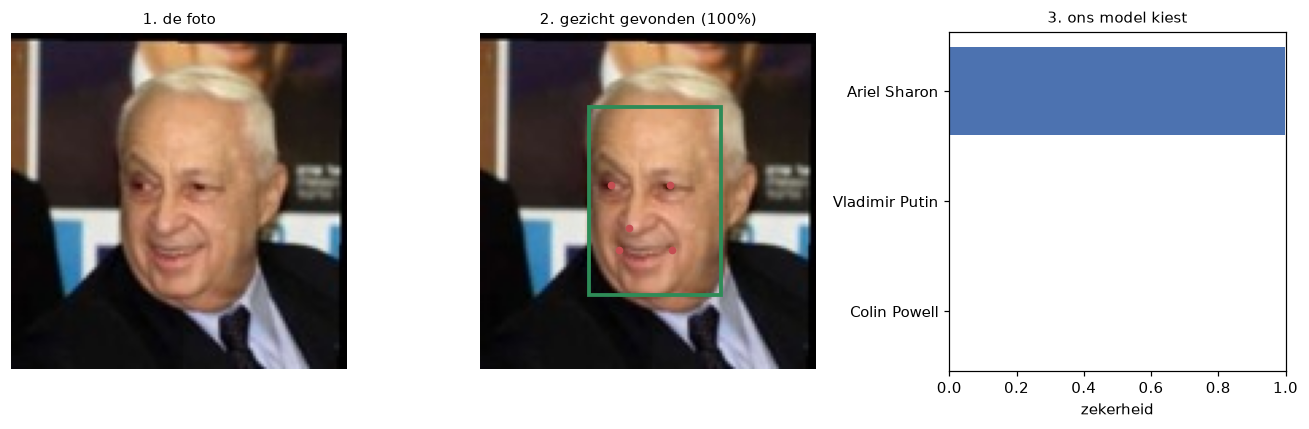

In [30]:
fig, (a, b, c) = plt.subplots(1, 3, figsize=(12, 4))

a.imshow(foto); a.set_title("1. de foto", fontsize=10); a.axis("off")

b.imshow(foto)
x, y_, w, h = detectie["box"]
b.add_patch(plt.Rectangle((x, y_), w, h, fill=False, ec="#2E8B57", lw=2.5))
for (px, py) in detectie["keypoints"].values():
    b.plot(px, py, "o", ms=4, color="#C44E52")
b.set_title(f"2. gezicht gevonden ({detectie['confidence']:.0%})", fontsize=10); b.axis("off")

c.barh([n for n, _ in voorspelling][::-1], [k for _, k in voorspelling][::-1], color="#4C72B0")
c.set_xlim(0, 1); c.set_xlabel("zekerheid")
c.set_title("3. ons model kiest", fontsize=10)

plt.tight_layout()
plt.show()

### En als het iemand is die het model niet kent?

Een classifier kiest **altijd** een naam uit de lijst die hij kent — ook als jouw gezicht er
helemaal niet bij zit. Dat is een echt probleem zodra je zo'n systeem loslaat op de wereld.

De oplossing komt uit §4: kijk niet naar de classifier, maar naar de **afstand**. Ligt het
dichtstbijzijnde bekende gezicht verder weg dan een drempel, dan is het antwoord "onbekend".

In [31]:
def herken_met_twijfel(pad, drempel=0.5):
    foto = np.array(Image.open(pad).convert("RGB"))
    kandidaten = detector.detect_faces(foto)
    if not kandidaten:
        return "geen gezicht gevonden", None

    beste = max(kandidaten, key=lambda d: d["confidence"])
    x, y_, w, h = beste["box"]
    dx, dy = int(w * 0.15), int(h * 0.15)
    x, y_ = max(0, x - dx), max(0, y_ - dy)
    uitsnede = np.array(Image.fromarray(foto[y_:y_ + h + 2 * dy, x:x + w + 2 * dx]).resize((160, 160)))
    vector = embedder.embeddings(uitsnede[None, ...])[0]

    # Afstand tot ELKE bekende foto; de kleinste telt.
    afstand_tot_bekend = 1 - embeddings[is_train] @ vector
    dichtstbij = np.argmin(afstand_tot_bekend)
    kleinste = afstand_tot_bekend[dichtstbij]
    naam = labels[is_train][dichtstbij]

    if kleinste > drempel:
        return f"ONBEKEND (dichtstbij was {naam} op afstand {kleinste:.2f})", kleinste
    return f"{naam}  (afstand {kleinste:.2f})", kleinste


print("Een paar testfoto's door de veilige versie:\n")
for k in np.where(~is_train)[0][:5]:
    uitkomst, afstand = herken_met_twijfel(paden_ok[k])
    klopt = "✓" if uitkomst.startswith(labels[k]) else "✗"
    print(f"  {klopt}  echt: {labels[k]:26s} ->  {uitkomst}")

if eigen_paden:
    print("\nEn jouw foto's:")
    for p in eigen_paden[:5]:
        uitkomst, _ = herken_met_twijfel(p)
        print(f"     {p.parent.name:20s} ->  {uitkomst}")
    print("\nStaat er ONBEKEND? Logisch: jouw gezicht zit niet in de 16 bekende personen.")
    print("Voeg je foto's toe aan data/gezichten/ en draai de notebook opnieuw,")
    print("dan leert het model jou er gewoon bij.")

Een paar testfoto's door de veilige versie:

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step
  ✓  echt: Ariel Sharon               ->  Ariel Sharon  (afstand 0.12)
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step
  ✓  echt: Ariel Sharon               ->  Ariel Sharon  (afstand 0.08)
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 64ms/step
  ✓  echt: Ariel Sharon               ->  Ariel Sharon  (afstand 0.07)
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step
  ✓  echt: Ariel Sharon               ->  Ariel Sharon  (afstand 0.06)
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step
  ✓  echt: Ariel Sharon               ->  Ariel Sharon  (afstand 0.09)
